In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

DATA_PATH = "../data/raw/cicids_ddos.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (225745, 79)


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,54865,3,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
1,55054,109,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2,55055,52,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
3,46236,34,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
4,54863,3,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN


In [2]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

Rows: 225745
Columns: 79

Column Names:
[' Destination Port', ' Flow Duration', ' Total Fwd Packets', ' Total Backward Packets', 'Total Length of Fwd Packets', ' Total Length of Bwd Packets', ' Fwd Packet Length Max', ' Fwd Packet Length Min', ' Fwd Packet Length Mean', ' Fwd Packet Length Std', 'Bwd Packet Length Max', ' Bwd Packet Length Min', ' Bwd Packet Length Mean', ' Bwd Packet Length Std', 'Flow Bytes/s', ' Flow Packets/s', ' Flow IAT Mean', ' Flow IAT Std', ' Flow IAT Max', ' Flow IAT Min', 'Fwd IAT Total', ' Fwd IAT Mean', ' Fwd IAT Std', ' Fwd IAT Max', ' Fwd IAT Min', 'Bwd IAT Total', ' Bwd IAT Mean', ' Bwd IAT Std', ' Bwd IAT Max', ' Bwd IAT Min', 'Fwd PSH Flags', ' Bwd PSH Flags', ' Fwd URG Flags', ' Bwd URG Flags', ' Fwd Header Length', ' Bwd Header Length', 'Fwd Packets/s', ' Bwd Packets/s', ' Min Packet Length', ' Max Packet Length', ' Packet Length Mean', ' Packet Length Std', ' Packet Length Variance', 'FIN Flag Count', ' SYN Flag Count', ' RST Flag Count', ' PSH Fla

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 225745 entries, 0 to 225744
Data columns (total 79 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0    Destination Port             225745 non-null  int64  
 1    Flow Duration                225745 non-null  int64  
 2    Total Fwd Packets            225745 non-null  int64  
 3    Total Backward Packets       225745 non-null  int64  
 4   Total Length of Fwd Packets   225745 non-null  int64  
 5    Total Length of Bwd Packets  225745 non-null  int64  
 6    Fwd Packet Length Max        225745 non-null  int64  
 7    Fwd Packet Length Min        225745 non-null  int64  
 8    Fwd Packet Length Mean       225745 non-null  float64
 9    Fwd Packet Length Std        225745 non-null  float64
 10  Bwd Packet Length Max         225745 non-null  int64  
 11   Bwd Packet Length Min        225745 non-null  int64  
 12   Bwd Packet Length Mean       225745 non-nul

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Destination Port,225745.0,8.879619e+03,1.975465e+04,0.0,80.0,80.0,80.0,65532.0
Flow Duration,225745.0,1.624165e+07,3.152437e+07,-1.0,71180.0,1452333.0,8805237.0,119999937.0
Total Fwd Packets,225745.0,4.874916e+00,1.542287e+01,1.0,2.0,3.0,5.0,1932.0
Total Backward Packets,225745.0,4.572775e+00,2.175536e+01,0.0,1.0,4.0,5.0,2942.0
Total Length of Fwd Packets,225745.0,9.394633e+02,3.249403e+03,0.0,26.0,30.0,63.0,183012.0
...,...,...,...,...,...,...,...,...
Active Min,225745.0,1.776201e+05,7.842602e+05,0.0,0.0,0.0,1862.0,100000000.0
Idle Mean,225745.0,1.032214e+07,2.185303e+07,0.0,0.0,0.0,8239725.0,120000000.0
Idle Std,225745.0,3.611943e+06,1.275689e+07,0.0,0.0,0.0,0.0,65300000.0
Idle Max,225745.0,1.287813e+07,2.692126e+07,0.0,0.0,0.0,8253838.0,120000000.0


In [5]:
df.columns = df.columns.str.strip()

print(df.columns.tolist())

['Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Min Packet Length', 'Max Packet Length', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'URG Flag Count', 'CWE Flag Count', 'ECE Flag Count

In [6]:
df["Destination Port"]
df["Flow Duration"]
df["Label"]

0         BENIGN
1         BENIGN
2         BENIGN
3         BENIGN
4         BENIGN
           ...  
225740    BENIGN
225741    BENIGN
225742    BENIGN
225743    BENIGN
225744    BENIGN
Name: Label, Length: 225745, dtype: object

In [7]:
print(df["Label"].value_counts())


Label
DDoS      128027
BENIGN     97718
Name: count, dtype: int64


In [8]:
print(df["Label"].value_counts(normalize=True) * 100)

Label
DDoS      56.713105
BENIGN    43.286895
Name: proportion, dtype: float64


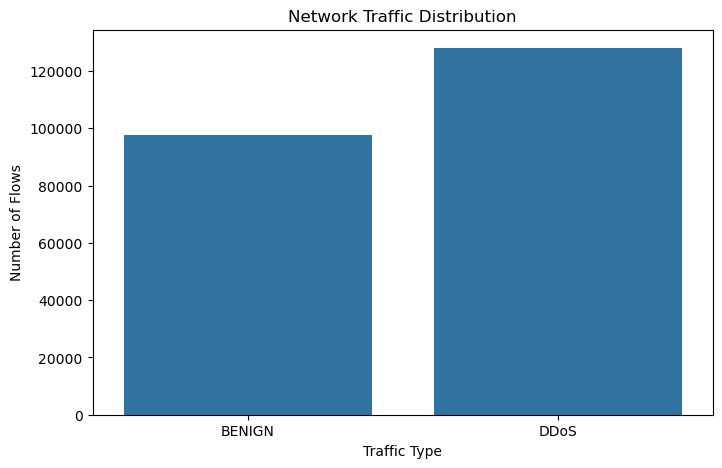

In [9]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Label")

plt.title("Network Traffic Distribution")
plt.xlabel("Traffic Type")
plt.ylabel("Number of Flows")

plt.show()

In [10]:
missing = df.isnull().sum()

missing = missing[missing > 0].sort_values(ascending=False)

print(missing)

Flow Bytes/s    4
dtype: int64


In [11]:
print("Positive infinity:", np.isinf(df.select_dtypes(include=np.number)).sum().sum())

Positive infinity: 64


In [12]:
duplicates = df.duplicated().sum()

print("Duplicate rows:", duplicates)

Duplicate rows: 2633


In [13]:
important_features = [
    "Destination Port",
    "Flow Duration",
    "Total Fwd Packets",
    "Total Backward Packets",
    "Total Length of Fwd Packets",
    "Total Length of Bwd Packets",
    "Flow Bytes/s",
    "Flow Packets/s",
    "SYN Flag Count",
    "RST Flag Count",
    "ACK Flag Count",
    "Label"
]

df[important_features].head()

,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Flow Bytes/s,Flow Packets/s,SYN Flag Count,RST Flag Count,ACK Flag Count,Label
0,54865,3,2,0,12,0,4.000000e+06,666666.66670,0,0,1,BENIGN
1,55054,109,1,1,6,6,1.100917e+05,18348.62385,0,0,1,BENIGN
2,55055,52,1,1,6,6,2.307692e+05,38461.53846,0,0,1,BENIGN
3,46236,34,1,1,6,6,3.529412e+05,58823.52941,0,0,1,BENIGN
4,54863,3,2,0,12,0,4.000000e+06,666666.66670,0,0,1,BENIGN


In [14]:
df.groupby("Label")[
    [
        "Flow Duration",
        "Total Fwd Packets",
        "Total Backward Packets",
        "Flow Bytes/s",
        "Flow Packets/s"
    ]
].mean()

,Flow Duration,Total Fwd Packets,Total Backward Packets,Flow Bytes/s,Flow Packets/s
Label,,,,,
BENIGN,1.530626e+07,5.402229,6.298205,inf,inf
DDoS,1.695559e+07,4.472439,3.255821,inf,inf


In [15]:
df["Label_encoded"] = df["Label"].map({
    "BENIGN": 0,
    "DDoS": 1
})

In [16]:
correlation = df.select_dtypes(include=np.number).corr()["Label_encoded"]

correlation = correlation.sort_values(ascending=False)

print(correlation.head(15))
print(correlation.tail(15))

Label_encoded             1.000000
Bwd Packet Length Mean    0.603299
Avg Bwd Segment Size      0.603299
Bwd Packet Length Max     0.577323
Bwd Packet Length Std     0.576155
Packet Length Mean        0.454283
Average Packet Size       0.453472
Packet Length Std         0.443749
Max Packet Length         0.414399
Packet Length Variance    0.408089
PSH Flag Count            0.247740
Flow IAT Std              0.129630
Flow IAT Mean             0.127503
Fwd IAT Max               0.105457
Flow IAT Max              0.100654
Name: Label_encoded, dtype: float64
Bwd Packet Length Min   -0.365667
min_seg_size_forward    -0.407315
Min Packet Length       -0.427396
URG Flag Count          -0.463190
Destination Port        -0.509798
Bwd PSH Flags                 NaN
Fwd URG Flags                 NaN
Bwd URG Flags                 NaN
CWE Flag Count                NaN
Fwd Avg Bytes/Bulk            NaN
Fwd Avg Packets/Bulk          NaN
Fwd Avg Bulk Rate             NaN
Bwd Avg Bytes/Bulk            N